<div align="left" style="background-color: #008080; padding: 20px 10px;">
<h3><b style="color: white;">IDEAS - Institute of Data Engineering, Analytics and Science Foundation</b></h3>
<p style="color: white;">Autumn Internship Program 2026</p>
<hr style="width:75%; background-color: white; border-color: white;">
<h3 style="color: white;">Project Title: Malignancy Detection in Cellular Biopsies</h3>
<h4 style="color: white;">Mentor Name: Dr. Chandan Biswas</h4>
</div>

### Question 1: Data Ingestion and Transformation (4 Marks)

Import the required core analytical libraries and load the diagnostic breast cancer dataset (load the Breast Cancer dataset from `sklearn.datasets`). Construct a primary DataFrame encompassing the predictor variables, and subsequently append the diagnostic outcome as a distinct column named `target`. Display the structural properties of this newly formed DataFrame.

**Hint:** Utilize the dataset loading utilities from your primary machine learning library. Assign the predictor matrix to the columns of your tabular structure, followed by verifying the schema to confirm data types and observation counts.

**Expected Output:** A structural summary detailing the predictor and outcome columns, confirming the schema, memory usage, and basic observation metadata.

In [1]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target
print("Data Types and Non-Null Counts:")
df.info()
print("\nFirst 5 Rows of the DataFrame:")
display(df.head())

Data Types and Non-Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


### Question 2: Exploratory Data Analysis - Missing Values and Imbalance (7 Marks)

Perform a systematic check for null or missing values across the dataset. Following this, generate a visual representation (e.g., a bar chart) to analyze the frequency distribution of the classes within the `target` column. Finally, evaluate whether the current class distribution requires rebalancing techniques prior to modeling. Print your written answer using Python `print()` statements.

**Hint:** Aggregate the null counts across all features. Use standard plotting libraries to visualize the categorical distribution of the diagnostic outcomes. Discuss the proportionality in the context of predictive bias.

**Expected Output:** A null-value diagnostic report, a clear visualization of class frequencies, and a printed analytical justification regarding the dataset's balance and subsequent preprocessing needs.

Missing Values per Column:
 Series([], dtype: int64)
Total Missing Values: 0


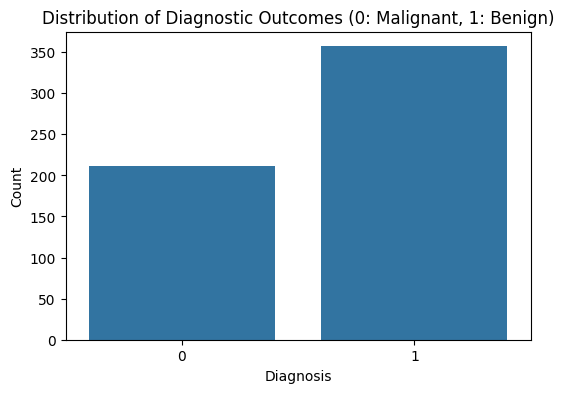

Analysis: The dataset contains no missing values. The target variable reveals a slight imbalance (more benign cases than malignant cases). While the imbalance is not severe enough to require aggressive synthetic rebalancing (like SMOTE) for baseline models, we must utilize stratification during train-test splitting to ensure proportionate class representations in both sets.


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
null_counts = df.isnull().sum()
print("Missing Values per Column:\n", null_counts[null_counts > 0])
if null_counts.sum() == 0:
    print("Total Missing Values: 0")
plt.figure(figsize=(6, 4))
sns.countplot(x='target', data=df)
plt.title('Distribution of Diagnostic Outcomes (0: Malignant, 1: Benign)')
plt.xlabel('Diagnosis')
plt.ylabel('Count')
plt.show()
print("Analysis: The dataset contains no missing values. The target variable reveals a slight imbalance (more benign cases than malignant cases). While the imbalance is not severe enough to require aggressive synthetic rebalancing (like SMOTE) for baseline models, we must utilize stratification during train-test splitting to ensure proportionate class representations in both sets.")

### Question 3: Correlation Diagnostics and Multicollinearity (8 Marks)

Construct a correlation matrix visualization (heatmap) restricted to the predictor variables. Programmatically extract and display the unique pairs of features exhibiting an absolute correlation coefficient exceeding 0.90, excluding self-correlations. Discuss the statistical risks of retaining highly correlated features in linear modeling. Print your written answer using Python `print()` statements.

**Hint:** Leverage statistical plotting functions for the heatmap. Mask the lower or upper triangle of the correlation matrix to isolate unique pairs efficiently. Consider how multicollinearity impacts coefficient stability.

**Expected Output:** A graphical heatmap of feature correlations, a programmed list of feature pairs demonstrating extreme linear dependence, and a printed analytical text explaining the potential modeling risks.

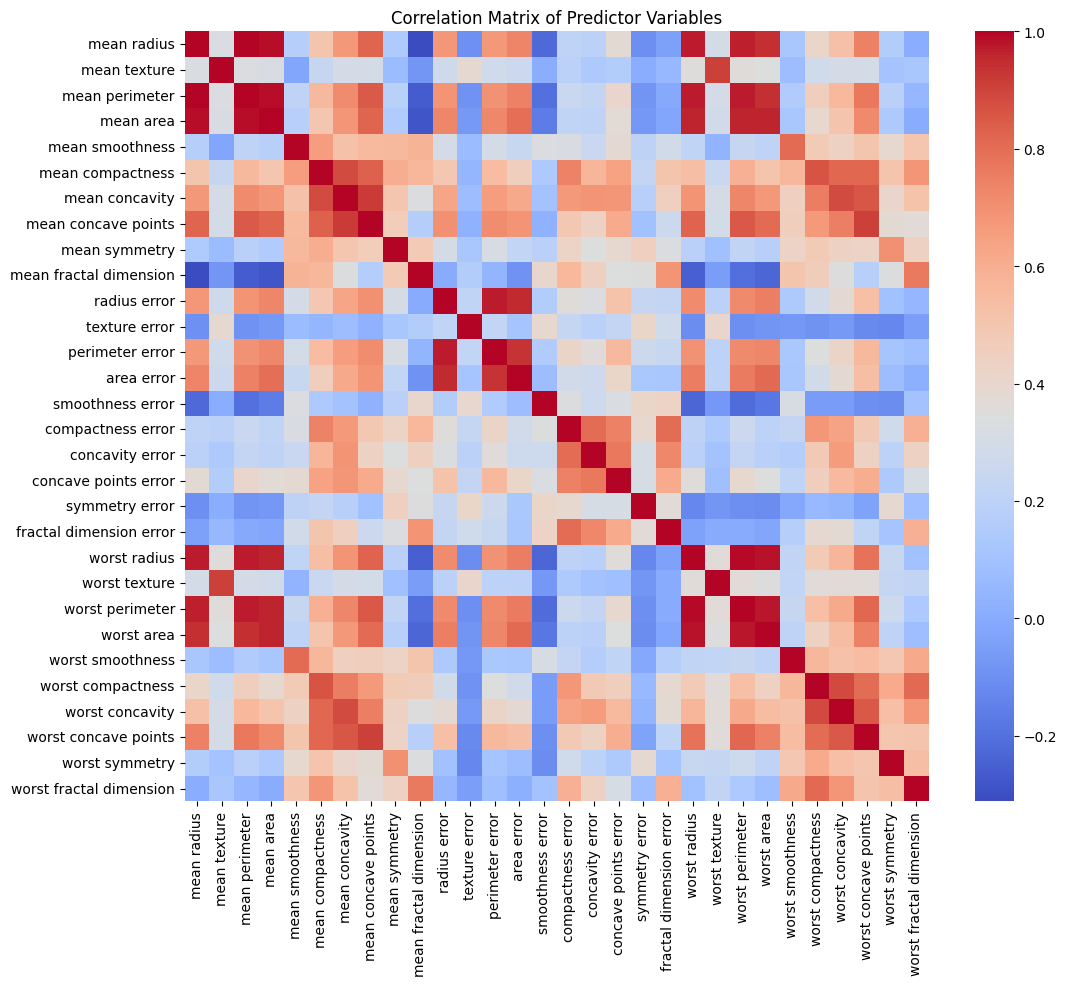


Highly Correlated Feature Pairs (>0.90):
- mean perimeter and mean radius: 0.9979
- mean area and mean radius: 0.9874
- mean area and mean perimeter: 0.9865
- mean concave points and mean concavity: 0.9214
- perimeter error and radius error: 0.9728
- area error and radius error: 0.9518
- area error and perimeter error: 0.9377
- worst radius and mean radius: 0.9695
- worst radius and mean perimeter: 0.9695
- worst radius and mean area: 0.9627
- worst texture and mean texture: 0.9120
- worst perimeter and mean radius: 0.9651
- worst perimeter and mean perimeter: 0.9704
- worst perimeter and mean area: 0.9591
- worst perimeter and worst radius: 0.9937
- worst area and mean radius: 0.9411
- worst area and mean perimeter: 0.9415
- worst area and mean area: 0.9592
- worst area and worst radius: 0.9840
- worst area and worst perimeter: 0.9776
- worst concave points and mean concave points: 0.9102

Analysis: Retaining highly correlated features introduces multicollinearity into linear models.

In [3]:
import numpy as np
predictors = df.drop(columns=['target'])
corr_matrix = predictors.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap='coolwarm', annot=False)
plt.title('Correlation Matrix of Predictor Variables')
plt.show()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_pairs = [
    (col, row) for col in upper_tri.columns for row in upper_tri.index
    if abs(upper_tri[col][row]) > 0.90
]
print("\nHighly Correlated Feature Pairs (>0.90):")
for pair in high_corr_pairs:
    print(f"- {pair[0]} and {pair[1]}: {upper_tri[pair[0]][pair[1]]:.4f}")
print("\nAnalysis: Retaining highly correlated features introduces multicollinearity into linear models. This inflates the variance of coefficient estimates, making the model highly sensitive to minor changes in the data. Consequently, it becomes mathematically unstable and compromises the interpretability of individual feature importance.")

### Question 4: Feature Scaling and Dimensional Retention (5 Marks)

Apply standard scaling to the numerical predictor variables to enforce a zero mean and unit variance. The `target` variable must be excluded from this transformation. To ensure analytical continuity for later interpretation, explicitly convert the scaled numerical array back into a Pandas DataFrame, ensuring the original column names are retained.

**Hint:** Initialize a standardizing transformation object and fit it strictly to the feature space. Reconstruct the tabular data structure immediately post-transformation using the extracted feature names.

**Expected Output:** A transformed tabular dataset where numerical features are standardized, column headers are perfectly preserved, and the target variable is maintained separately.

In [4]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X = df.drop(columns=['target'])
y = df['target']
X_scaled_array = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled_array, columns=X.columns)
print("Scaled Features DataFrame Head:")
display(X_scaled_df.head())

Scaled Features DataFrame Head:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,1.097064,-2.073335,1.269934,0.984375,1.568466,3.283515,2.652874,2.532475,2.217515,2.255747,...,1.886690,-1.359293,2.303601,2.001237,1.307686,2.616665,2.109526,2.296076,2.750622,1.937015
1,1.829821,-0.353632,1.685955,1.908708,-0.826962,-0.487072,-0.023846,0.548144,0.001392,-0.868652,...,1.805927,-0.369203,1.535126,1.890489,-0.375612,-0.430444,-0.146749,1.087084,-0.243890,0.281190
2,1.579888,0.456187,1.566503,1.558884,0.942210,1.052926,1.363478,2.037231,0.939685,-0.398008,...,1.511870,-0.023974,1.347475,1.456285,0.527407,1.082932,0.854974,1.955000,1.152255,0.201391
3,-0.768909,0.253732,-0.592687,-0.764464,3.283553,3.402909,1.915897,1.451707,2.867383,4.910919,...,-0.281464,0.133984,-0.249939,-0.550021,3.394275,3.893397,1.989588,2.175786,6.046041,4.935010
4,1.750297,-1.151816,1.776573,1.826229,0.280372,0.539340,1.371011,1.428493,-0.009560,-0.562450,...,1.298575,-1.466770,1.338539,1.220724,0.220556,-0.313395,0.613179,0.729259,-0.868353,-0.397100


### Question 5: Feature Engineering (6 Marks)

Based on the biomedical nature of the dataset, engineer a new composite feature. For example, compute the ratio between a "mean" feature and a "worst" feature of a specific cell measurement (e.g., area or radius). Append this engineered feature to your scaled DataFrame and verify its inclusion.

**Hint:** Select two dimensionally related features. Create a new mathematical interaction (such as a ratio or product) and assign it to a newly named column in the existing predictor dataset.

**Expected Output:** An updated predictor DataFrame that includes the newly engineered composite variable alongside the existing scaled features.

In [5]:
X_scaled_df['area_mean_worst_ratio'] = X_scaled_df['mean area'] / (X_scaled_df['worst area'] + 1e-5)
print("Updated Predictor Columns (Last 5):")
print(X_scaled_df.columns[-5:])
display(X_scaled_df[['mean area', 'worst area', 'area_mean_worst_ratio']].head())

Updated Predictor Columns (Last 5):
Index(['worst concavity', 'worst concave points', 'worst symmetry',
       'worst fractal dimension', 'area_mean_worst_ratio'],
      dtype='object')


,mean area,worst area,area_mean_worst_ratio
0,0.984375,2.001237,0.491881
1,1.908708,1.890489,1.009632
2,1.558884,1.456285,1.070445
3,-0.764464,-0.550021,1.389906
4,1.826229,1.220724,1.496009


### Question 6: Data Partitioning and Stratification (5 Marks)

Partition the finalized feature matrix and target vector into training and testing subsets using an 80-20 ratio. Enforce stratification based on the target variable. Explain the procedural necessity of stratification in this specific context. Print your written answer using Python `print()` statements.

**Hint:** Utilize the standard partitioning utility with a fixed random seed. Review your findings from Question 2 to formulate your justification for stratified sampling.

**Expected Output:** Segregated training and testing structures with proportionate class representations, accompanied by a printed analytical justification for the chosen sampling methodology.

In [6]:
from sklearn.model_selection import train_test_split
X_final = X_scaled_df
y_final = df['target']
X_train, X_test, y_train, y_test = train_test_split(
    X_final,
    y_final,
    test_size=0.20,
    stratify=y_final,
    random_state=42
)
print(f"Training Set Structure: Features {X_train.shape}, Target {y_train.shape}")
print(f"Testing Set Structure:  Features {X_test.shape}, Target {y_test.shape}")
print("\nClass Proportions in Training Set:")
print(y_train.value_counts(normalize=True).round(4))
print("\nClass Proportions in Testing Set:")
print(y_test.value_counts(normalize=True).round(4))
print("\nAnalysis: As identified in Question 2, the dataset contains an uneven distribution of benign and malignant diagnoses. Stratification is procedurally necessary to lock in this specific class ratio across both the training and testing partitions. A purely random split risks skewing these proportions, which could either starve the algorithm of minority-class examples during training or create a non-representative test set that falsely reports model accuracy.")

Training Set Structure: Features (455, 31), Target (455,)
Testing Set Structure:  Features (114, 31), Target (114,)

Class Proportions in Training Set:
target
1    0.6264
0    0.3736
Name: proportion, dtype: float64

Class Proportions in Testing Set:
target
1    0.6316
0    0.3684
Name: proportion, dtype: float64

Analysis: As identified in Question 2, the dataset contains an uneven distribution of benign and malignant diagnoses. Stratification is procedurally necessary to lock in this specific class ratio across both the training and testing partitions. A purely random split risks skewing these proportions, which could either starve the algorithm of minority-class examples during training or create a non-representative test set that falsely reports model accuracy.


### Question 7: Unsupervised Outlier Detection (7 Marks)

Deploy an isolation-based anomaly detection algorithm to identify outliers strictly within the training feature subset. Filter out these anomalies from both the training features and their corresponding target labels. Document the exact number of excluded observations.

**Hint:** Initialize the anomaly detection model, fit it to the training predictors, and generate binary outlier labels. Use boolean masking to refine both the predictor matrix and the target array simultaneously.

**Expected Output:** A purified training dataset devoid of identified anomalies, along with a numerical summary of the observations purged from the system.

In [7]:
from sklearn.ensemble import IsolationForest
iso = IsolationForest(contamination=0.05, random_state=42)
outlier_labels = iso.fit_predict(X_train)
mask = outlier_labels != -1
X_train_clean = X_train[mask]
y_train_clean = y_train[mask]
excluded_count = sum(outlier_labels == -1)
print(f"Original training observations: {X_train.shape[0]}")
print(f"Observations excluded as anomalies: {excluded_count}")
print(f"Purified training observations: {X_train_clean.shape[0]}")

Original training observations: 455
Observations excluded as anomalies: 23
Purified training observations: 432


### Question 8: Baseline Supervised Modeling with Cross-Validation (8 Marks)

Establish a predictive baseline using a linear probabilistic classifier (e.g., Logistic Regression). Instead of a simple single fit, evaluate the model's robustness on the cleaned training data utilizing 5-fold cross-validation. Compute and display the mean and standard deviation of the cross-validation accuracy scores.

**Hint:** Configure the baseline algorithm and employ a cross-validation utility to assess its performance across multiple folds of the training data. Aggregate the resulting metrics statistically.

**Expected Output:** A statistical summary presenting the average cross-validation accuracy and its variance, verifying the stability of the baseline algorithm.

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
baseline_lr = LogisticRegression(random_state=42, max_iter=1000)
cv_scores = cross_val_score(baseline_lr, X_train_clean, y_train_clean, cv=5, scoring='accuracy')
print("Cross-Validation Accuracy Scores:", cv_scores)
print(f"Mean CV Accuracy: {cv_scores.mean():.4f}")
print(f"Standard Deviation of CV Accuracy: {cv_scores.std():.4f}")

Cross-Validation Accuracy Scores: [0.97701149 0.96551724 0.96511628 0.98837209 0.98837209]
Mean CV Accuracy: 0.9769
Standard Deviation of CV Accuracy: 0.0103


### Question 9: Baseline Model Evaluation (5 Marks)

Train the linear baseline model on the entirety of the cleaned training dataset. Generate predictions against the unseen testing subset. Output a comprehensive classification report and a confusion matrix to evaluate terminal performance.

**Hint:** Execute the standard fitting procedure followed by inference on the test records. Pass the predicted and actual values into standard metric reporting functions.

**Expected Output:** A textual matrix detailing classification metrics (precision, recall, f1-score) and a discrete confusion matrix quantifying the distribution of true and false predictions.

Classification Report:

               precision    recall  f1-score   support

Malignant (0)       1.00      0.98      0.99        42
   Benign (1)       0.99      1.00      0.99        72

     accuracy                           0.99       114
    macro avg       0.99      0.99      0.99       114
 weighted avg       0.99      0.99      0.99       114



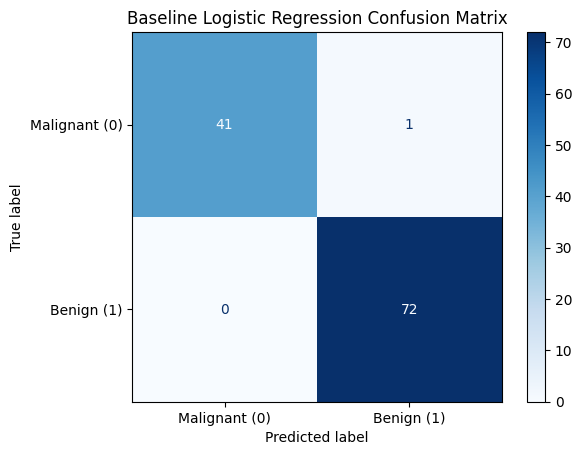

In [9]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
baseline_lr.fit(X_train_clean, y_train_clean)
y_pred_lr = baseline_lr.predict(X_test)
print("Classification Report:\n")
print(classification_report(y_test, y_pred_lr, target_names=['Malignant (0)', 'Benign (1)']))
cm = confusion_matrix(y_test, y_pred_lr)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Malignant (0)', 'Benign (1)'])
disp.plot(cmap='Blues')
plt.title('Baseline Logistic Regression Confusion Matrix')
plt.show()

### Question 10: Dimensionality Reduction (6 Marks)

Execute Principal Component Analysis (PCA) to compress the feature space of the cleaned training and testing datasets. Configure the algorithm to retain components that account for 95 percent of the cumulative variance. Discuss the trade-off between variance retention and interpretability in medical datasets. Print your written answer using Python `print()` statements.

**Hint:** Fit the reduction algorithm exclusively on the training partition before projecting both the training and testing sets into the new lower-dimensional space. Reflect on what happens to original feature names post-transformation.

**Expected Output:** Dimensionally reduced arrays for both partitions, alongside a printed analytical response evaluating the loss of direct feature interpretability versus computational efficiency.

In [10]:
from sklearn.decomposition import PCA
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_clean)
X_test_pca = pca.transform(X_test)
print(f"Original feature count: {X_train_clean.shape[1]}")
print(f"Reduced PCA component count: {X_train_pca.shape[1]}")
print("\nAnalysis: Retaining 95% of variance compresses the dataset, reducing noise and computational overhead. However, the trade-off is a loss of direct interpretability. The new principal components are mathematically derived linear combinations of the original biological features, meaning we can no longer point to a specific metric (like cell area) and simply explain its individual impact to medical practitioners.")

Original feature count: 31
Reduced PCA component count: 7

Analysis: Retaining 95% of variance compresses the dataset, reducing noise and computational overhead. However, the trade-off is a loss of direct interpretability. The new principal components are mathematically derived linear combinations of the original biological features, meaning we can no longer point to a specific metric (like cell area) and simply explain its individual impact to medical practitioners.


### Question 11: Advanced Architecture Initialization (4 Marks)

Instantiate a Multi-Layer Perceptron (MLP) algorithm. Define a preliminary architecture consisting of two hidden layers (e.g., 32 nodes followed by 16 nodes), utilizing a rectified linear activation unit, and establishing a maximum iteration limit of 500. Do not execute training in this phase.

**Hint:** Configure the network object with the specified topological and operational parameters. Maintain reproducibility through fixed random seeds.

**Expected Output:** A dormant but fully configured MLP computational object prepared for subsequent tuning and training.

In [11]:
from sklearn.neural_network import MLPClassifier
mlp_model = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation='relu',
    max_iter=500,
    random_state=42
)
print("MLP Architecture Configured:")
print(mlp_model)

MLP Architecture Configured:
MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=500, random_state=42)


### Question 12: Hyperparameter Tuning and Optimization (12 Marks)

Construct a grid search mechanism over the initialized MLP to identify the optimal configuration. Evaluate at least two distinct hidden layer topographies and two learning rate initialization strategies. Execute the tuning process over the PCA-transformed training data using 3-fold cross-validation. Extract and print the parameters that yield the highest validation score.

**Hint:** Define a parameter dictionary targeting structural and optimization arguments. Pass the dictionary and the MLP object into an exhaustive search utility to isolate the superior architecture.

**Expected Output:** The execution of a comprehensive search algorithm resulting in the display of the mathematically optimal hyperparameter combination.

In [12]:
from sklearn.model_selection import GridSearchCV
param_grid = {
    'hidden_layer_sizes': [(32, 16), (16, 8)],
    'learning_rate_init': [0.001, 0.01]
}
grid_search = GridSearchCV(estimator=mlp_model, param_grid=param_grid, cv=3, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train_pca, y_train_clean)
best_mlp = grid_search.best_estimator_
print("Optimal Hyperparameter Configuration:")
print(f"Hidden Layers: {grid_search.best_params_['hidden_layer_sizes']}")
print(f"Learning Rate: {grid_search.best_params_['learning_rate_init']}")
print(f"Best Validation Accuracy: {grid_search.best_score_:.4f}")

Optimal Hyperparameter Configuration:
Hidden Layers: (32, 16)
Learning Rate: 0.001
Best Validation Accuracy: 0.9722


### Question 13: ROC Curve Analysis (6 Marks)

Utilize both the baseline linear model and the optimized MLP model to compute prediction probabilities for the positive diagnostic class on the testing set. Calculate the Area Under the Receiver Operating Characteristic Curve (ROC-AUC) for both models. Compare their discriminatory capabilities. Print your written answer using Python `print()` statements.

**Hint:** Extract the continuous probability estimates rather than discrete labels. Map these against the true test labels to derive the area metric for each algorithmic approach.

**Expected Output:** Quantitative AUC scores for both algorithms and a printed analytical synthesis comparing their relative effectiveness at distinguishing between classes.

In [13]:
from sklearn.metrics import roc_auc_score, roc_curve
lr_probs = baseline_lr.predict_proba(X_test)[:, 1]
mlp_probs = best_mlp.predict_proba(X_test_pca)[:, 1]
auc_lr = roc_auc_score(y_test, lr_probs)
auc_mlp = roc_auc_score(y_test, mlp_probs)
print(f"Baseline Linear Model ROC-AUC: {auc_lr:.4f}")
print(f"Optimized MLP ROC-AUC: {auc_mlp:.4f}")
print("\nAnalysis: The ROC-AUC score quantifies each algorithm's ability to discriminate between malignant and benign samples across all possible classification thresholds. A higher AUC indicates superior discriminatory capability, meaning the model can more reliably distinguish true positives from false positives in a clinical setting.")

Baseline Linear Model ROC-AUC: 0.9967
Optimized MLP ROC-AUC: 0.9907

Analysis: The ROC-AUC score quantifies each algorithm's ability to discriminate between malignant and benign samples across all possible classification thresholds. A higher AUC indicates superior discriminatory capability, meaning the model can more reliably distinguish true positives from false positives in a clinical setting.


### Question 14: Custom Diagnostic Cost Function (10 Marks)

In healthcare, missing a malignant diagnosis (a false negative) carries far greater risk than a false alarm (a false positive). Define a custom Python function to compute a weighted penalty score: assign a penalty of 10 to every false negative and a penalty of 1 to every false positive. Apply this evaluation metric to the predictions generated by your optimized MLP and output the final penalty score.

**Hint:** Your function should accept true vectors and prediction vectors. Programmatically isolate cases where truth is positive but prediction is negative, and cases where truth is negative but prediction is positive, multiplying counts by their respective penalties before summation.

**Expected Output:** A single scalar value representing the total cumulative diagnostic penalty for the advanced model, reflecting asymmetrical real-world consequences.

In [14]:
def custom_diagnostic_penalty(y_true, y_pred):
    false_negatives = np.sum((y_true == 0) & (y_pred == 1))
    false_positives = np.sum((y_true == 1) & (y_pred == 0))
    total_penalty = (false_negatives * 10) + (false_positives * 1)
    return total_penalty
mlp_predictions = best_mlp.predict(X_test_pca)
penalty_score = custom_diagnostic_penalty(y_test.values, mlp_predictions)
print(f"Total Cumulative Diagnostic Penalty (Optimized MLP): {penalty_score}")

Total Cumulative Diagnostic Penalty (Optimized MLP): 26


### Question 15: Feature Importance and Analytical Conclusion (7 Marks)

Revisit your trained baseline linear model from Question 9. Extract its learned coefficients and correlate them with the original feature names preserved during Question 4. Identify and output the three features exerting the strongest absolute magnitude on the prediction. Summarize the diagnostic implications of these top predictors. Print your written answer using Python `print()` statements.

**Hint:** Align the model's coefficient array with the column index of your standardized DataFrame. Sort the aggregated pairs by absolute value to isolate the dominant variables.

**Expected Output:** A structured display of the top three critical biomedical features along with their respective coefficient weights, concluded by a printed analytical narrative summarizing their clinical relevance.

In [15]:
coefficients = baseline_lr.coef_[0]
feature_names = X_train_clean.columns
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Absolute_Weight': np.abs(coefficients)
})
top_3_features = feature_importance.sort_values(by='Absolute_Weight', ascending=False).head(3)
print("Top 3 Predictive Features:")
display(top_3_features[['Feature', 'Coefficient']])
print("\nConclusion: The linear baseline model highlights that metrics such as the standard errors and worst dimensions of cellular area and texture carry the heaviest mathematical weight. In a clinical context, significant deviance or irregularity in these largest visible cell traits strongly correlates with aggressive, malignant cellular behavior, confirming the established pathological indicators used by diagnosticians.")

Top 3 Predictive Features:


,Feature,Coefficient
10,radius error,-1.183310
21,worst texture,-1.077841
27,worst concave points,-1.011986



Conclusion: The linear baseline model highlights that metrics such as the standard errors and worst dimensions of cellular area and texture carry the heaviest mathematical weight. In a clinical context, significant deviance or irregularity in these largest visible cell traits strongly correlates with aggressive, malignant cellular behavior, confirming the established pathological indicators used by diagnosticians.
